# TK 1 Analisis Numerik — Nomor 1
## Analisis Perpindahan Penumpang Antarhalte

Tahap ini melengkapi tugas **i–vii** pada PDF `TK_1_Anum_Gasal_26_27.pdf`,
halaman 3–5. Data yang dianalisis adalah keenam CSV yang tersedia di repo.
PDF menyebut kode A/B berdasarkan nomor kelompok, tetapi nama berkas repo
tidak mencantumkan kode; kecocokan kode kelompok perlu dicocokkan dengan sumber SCeLE.
Algoritma LU dan eliminasi banded diimplementasikan sendiri. NumPy digunakan
untuk penyimpanan, operasi aritmetika, dan pemeriksaan; tidak ada pemanggilan
solver, inverse, SVD, atau faktorisasi pustaka.

**Hasil audit pekerjaan awal:** i, iii, iv, dan v sudah konsisten secara numerik;
ii sudah benar dalam kode, tetapi penurunan matematis belum ditulis. Bagian ii
dilengkapi di bawah. Data mempunyai bandwidth $p=1,q=2$, sehingga istilah
Thomas-style berarti perluasan untuk band tersebut, dengan fill-in diagonal
atas ketiga; Thomas tridiagonal biasa akan menghilangkan koefisien penting.
Bagian vi–ix ditambahkan, termasuk condition number, pemeriksaan independen,
serta uji sensitivitas. Interpretasi halte dan rekomendasi tersedia pada commit lanjutan.
Semua output diperbarui lewat eksekusi ulang.


## 0. Setup dan Konfigurasi

Jalankan notebook dari direktori proyek; dataset berada di `data/T_<N>.csv`.
`TOL` dapat dikonfigurasi sesuai kebutuhan toleransi numerik. Vektor menggunakan bentuk `(N,)`.

In [1]:
from pathlib import Path
import numpy as np

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output/no1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MATRIX_SIZES = [16, 32, 64, 128, 256, 512]
TOL = 1e-10


def max_abs_diff(x, y):
    """Selisih absolut maksimum dua vektor berbentuk (N,)."""
    return float(np.max(np.abs(x - y)))


**Output/check:** Sel setup mendefinisikan konfigurasi dan helper; tidak menghasilkan output.

## 1. Validasi Data

Setiap `data/T_<N>.csv` dibaca tanpa header. Matriks harus berdimensi
$N\times N$, memiliki elemen berhingga dan $T_{ij}\geq 0$, serta memenuhi
$\left|\sum_j T_{ij}-1\right|\leq\mathrm{TOL}$ untuk setiap baris.
Nonnegativitas diperiksa secara ketat; data tidak dipotong atau dinormalisasi ulang.

Untuk rantai Markov berhingga, distribusi stasioner tunggal **jika dan hanya jika**
terdapat tepat satu kelas komunikasi tertutup. Kelas komunikasi diperoleh dari
komponen terhubung kuat (SCC) graf berarah dengan sisi $i\to j$ jika $T_{ij}>0$.
SCC tertutup tidak memiliki sisi menuju SCC lain. Graf yang terhubung kuat
(irreducible) merupakan syarat cukup, tetapi bukan syarat perlu untuk ketunggalan.

Aperiodisitas diperlukan untuk konvergensi menuju distribusi stasioner dari setiap
kondisi awal, bukan untuk ketunggalan saja. Pada kelas tertutup yang irreducible,
satu self-loop positif sudah menjamin periode satu. Pemeriksaan ini merupakan
syarat cukup; jika tidak ada self-loop, periode belum disimpulkan.
Probabilitas positif sekecil apa pun tetap menjadi sisi; `TOL` hanya dipakai untuk
jumlah baris. Tidak ada solver atau faktorisasi yang digunakan.


In [2]:
def communication_classes(T):
    """SCC graf transisi dengan dua penelusuran DFS (Kosaraju)."""
    n = T.shape[0]
    outgoing = [np.flatnonzero(T[i] > 0).tolist() for i in range(n)]
    incoming = [[] for _ in range(n)]
    for i, neighbors in enumerate(outgoing):
        for j in neighbors:
            incoming[j].append(i)

    seen, order = set(), []
    for root in range(n):
        if root in seen:
            continue
        seen.add(root)
        stack = [(root, iter(outgoing[root]))]
        while stack:
            vertex, neighbors = stack[-1]
            neighbor = next(neighbors, None)
            if neighbor is None:
                order.append(vertex)
                stack.pop()
            elif neighbor not in seen:
                seen.add(neighbor)
                stack.append((neighbor, iter(outgoing[neighbor])))

    labels = [-1] * n
    classes = []
    for root in reversed(order):
        if labels[root] != -1:
            continue
        label = len(classes)
        labels[root] = label
        stack, members = [root], []
        while stack:
            vertex = stack.pop()
            members.append(vertex)
            for neighbor in incoming[vertex]:
                if labels[neighbor] == -1:
                    labels[neighbor] = label
                    stack.append(neighbor)
        classes.append(members)

    closed = [members for label, members in enumerate(classes)
              if all(labels[j] == label for i in members for j in outgoing[i])]
    return classes, closed


def validate_transition_matrix(T, N, tol=TOL):
    """Validasi T tanpa mengubah data; tolak matriks transisi yang tidak sah."""
    if not np.isfinite(tol) or tol < 0:
        raise ValueError("Toleransi harus berhingga dan nonnegatif.")
    if T.shape != (N, N) or N < 1:
        raise ValueError(f"Dimensi {T.shape}, seharusnya ({N}, {N}).")
    if not np.all(np.isfinite(T)):
        raise ValueError("Matriks mengandung NaN atau infinity.")
    minimum = float(np.min(T))
    if minimum < 0:
        raise ValueError(f"Elemen negatif ditemukan: minimum = {minimum}.")
    row_sums = np.sum(T, axis=1)
    row_error = float(np.max(np.abs(row_sums - 1.0)))
    if row_error > tol:
        raise ValueError(f"Galat jumlah baris {row_error:.3e} melebihi {tol:.3e}.")
    classes, closed = communication_classes(T)
    return {
        "shape": T.shape,
        "minimum": minimum,
        "nonnegative": minimum >= 0,
        "row_sums": row_sums,
        "max_row_sum_error": row_error,
        "communication_classes": classes,
        "closed_classes": closed,
        "irreducible": len(classes) == 1,
        "unique_stationary": len(closed) == 1,
        "aperiodic_closed_classes_confirmed": all(
            any(T[i, i] > 0 for i in members) for members in closed
        ),
    }


def load_transition_matrix(path, N, tol=TOL):
    """Baca CSV numerik dan kembalikan (T, hasil_validasi)."""
    T = np.loadtxt(path, delimiter=",", ndmin=2)
    return T, validate_transition_matrix(T, N, tol)


matrices = {}
validation_results = {}
print("N    dimensi      min(T)     nonnegatif  galat baris   SCC  tertutup  tunggal  aperiodik*")
for N in MATRIX_SIZES:
    path = DATA_DIR / f"T_{N}.csv"
    T, result = load_transition_matrix(path, N)
    matrices[N] = T
    validation_results[N] = result
    print(f"{N:<4} {str(T.shape):<12} {result['minimum']:.1e}    "
          f"{str(result['nonnegative']):<11} {result['max_row_sum_error']:.3e}     "
          f"{len(result['communication_classes']):<4} "
          f"{len(result['closed_classes']):<9} "
          f"{str(result['unique_stationary']):<8} "
          f"{result['aperiodic_closed_classes_confirmed']}")
print("* True: self-loop membuktikan aperiodisitas kelas tertutup; False: belum disimpulkan.")


N    dimensi      min(T)     nonnegatif  galat baris   SCC  tertutup  tunggal  aperiodik*
16   (16, 16)     0.0e+00    True        1.110e-16     1    1         True     True
32   (32, 32)     0.0e+00    True        2.220e-16     1    1         True     True
64   (64, 64)     0.0e+00    True        1.110e-16     1    1         True     True
128  (128, 128)   0.0e+00    True        2.220e-16     1    1         True     True
256  (256, 256)   0.0e+00    True        2.220e-16     1    1         True     True
512  (512, 512)   0.0e+00    True        2.220e-16     1    1         True     True
* True: self-loop membuktikan aperiodisitas kelas tertutup; False: belum disimpulkan.


**Interpretasi hasil:** Seluruh matriks transisi memiliki dimensi sesuai ukuran yang diberikan, yaitu $N\times N$, dengan $N\in\{16,32,64,128,256,512\}$. Nilai minimum setiap matriks adalah 0 sehingga tidak ditemukan probabilitas negatif. Galat maksimum jumlah baris berada pada orde $10^{-16}$, sehingga seluruh matriks memenuhi sifat row-stochastic hingga presisi floating-point. Analisis graf menunjukkan setiap matriks hanya memiliki satu strongly connected component (SCC) yang sekaligus merupakan satu-satunya kelas tertutup. Dengan demikian, rantai Markov memiliki distribusi steady state yang tunggal. Pemeriksaan aperiodisitas melalui keberadaan self-loop digunakan sebagai informasi tambahan mengenai perilaku konvergensi, bukan sebagai syarat keunikan distribusi steady state.

**Output/check:** `matrices[N]` menyimpan matriks asli dan `validation_results[N]` menyimpan diagnostik, termasuk vektor jumlah baris berbentuk `(N,)`. Sel berikut menguji graf irreducible, graf reducible dengan satu/dua kelas tertutup, rantai periodik, serta data tidak sah.


In [3]:
def check_data_validation():
    examples = [
        (np.array([[0.5, 0.5], [0.5, 0.5]]), True, True, True),
        (np.array([[0.0, 1.0], [0.0, 1.0]]), False, True, True),
        (np.array([[1.0, 0.0], [0.0, 1.0]]), False, False, True),
        (np.array([[0.0, 1.0], [1.0, 0.0]]), True, True, False),
        (np.array([[1.0 - 1e-12, 1e-12], [1e-12, 1.0 - 1e-12]]),
         True, True, True),
    ]
    for T, irreducible, unique, aperiodic in examples:
        result = validate_transition_matrix(T, 2)
        assert result["irreducible"] == irreducible
        assert result["unique_stationary"] == unique
        assert result["aperiodic_closed_classes_confirmed"] == aperiodic
        assert result["row_sums"].shape == (2,)
    for T in [np.zeros((2, 3)), np.array([[float("nan"), 0], [0, 1]]),
              np.array([[float("inf"), 0], [0, 1]]),
              np.array([[1.1, -0.1], [0, 1]]),
              np.array([[0.4, 0.4], [0, 1]])]:
        try:
            validate_transition_matrix(T, 2)
        except ValueError:
            pass
        else:
            raise AssertionError("Matriks tidak sah seharusnya ditolak.")
    print("Self-check validasi data: OK")


check_data_validation()


Self-check validasi data: OK


## 2. Formulasi dan Penanganan Singularitas — ii)

Misalkan $\pi^{(k)}_i=\Pr(X_k=i)$, dengan distribusi ditulis sebagai vektor
kolom. Hukum probabilitas total memberikan
$$\pi^{(k+1)}_j=\sum_{i=1}^N T_{ij}\pi^{(k)}_i,
\qquad \pi^{(k+1)}=T^T\pi^{(k)}.$$
Pada keadaan stasioner, $\pi^{(k+1)}=\pi^{(k)}=\pi$, sehingga
$A\pi=0$ untuk $A=I-T^T$.

Karena $T\mathbf1=\mathbf1$, maka $\mathbf1^T A=0$. Ada vektor null
kiri bukan nol, sehingga $A$ singular. Jumlah semua baris $A$ nol, yaitu
$A_{1,:}=-\sum_{i=2}^N A_{i,:}$. Dengan demikian, jika baris 2 sampai $N$
memenuhi $Az=0$, baris pertama juga memenuhi. Untuk rantai irreducible
pada dataset, $\operatorname{rank}(A)=N-1$ dan nullspace berdimensi satu,
dibentang distribusi stasioner positif $\pi$.

Ganti baris pertama dengan $e_1^T$ dan ruas kanan dengan $e_1$ persis
seperti soal. Sistem $Bz=b$ sekarang menetapkan $z_1=1$ dan $Az=0$.
Jika $Bx=0$, maka $Ax=0$, jadi $x=c\pi$; karena $x_1=0$ dan $\pi_1>0$,
diperoleh $c=0$. Ini membuktikan $B$ nonsingular. Solusinya adalah
$z=\pi/\pi_1$, sehingga $\mathbf1^Tz=1/\pi_1$, umumnya bukan satu.
Normalisasi $\pi=z/(\mathbf1^Tz)$ mengembalikan proporsi total satu.

Ketunggalan distribusi saja pada rantai reducible belum menjamin penggantian
ini berhasil: bila halte 1 transient, $\pi_1=0$, sehingga penetapan $z_1=1$
tidak cocok. Dataset di repo semuanya irreducible, jadi syarat di atas terpenuhi.
Identitas jumlah baris berlaku hingga galat pembulatan float64 pada data CSV;
residual persamaan yang diganti tetap diperiksa sesudah normalisasi.


In [4]:
def build_system(T):
    """Bentuk A, B, b; T harus matriks transisi yang telah divalidasi."""
    if not isinstance(T, np.ndarray) or T.ndim != 2:
        raise ValueError("T harus berupa NumPy array dua dimensi.")
    N = T.shape[0]
    if N == 0 or T.shape[1] != N:
        raise ValueError("T harus persegi dan tidak kosong.")
    I = np.eye(N)
    A = I - T.T
    B = A.copy()
    B[0, :] = 0
    B[0, 0] = 1
    b = np.zeros(N)
    b[0] = 1
    return A, B, b


def normalize_solution(z, tol=TOL):
    """Normalisasi arah stasioner z menjadi array baru dengan jumlah satu."""
    if not isinstance(z, np.ndarray) or z.ndim != 1:
        raise ValueError("z harus berupa NumPy array satu dimensi (N,).")
    if not np.isfinite(tol) or tol < 0:
        raise ValueError("Toleransi harus berhingga dan nonnegatif.")
    if not np.all(np.isfinite(z)):
        raise ValueError("z harus memiliki elemen berhingga.")
    denominator = np.sum(z)
    if not np.isfinite(denominator) or abs(denominator) <= tol:
        raise ValueError("Jumlah elemen z tidak berhingga atau terlalu dekat nol untuk normalisasi.")
    return z / denominator


systems = {}
structural_results = {}
print("N | shape A | shape B | ||1^T A||inf | row B1 valid | rows 2..N valid | b valid")
print("--- | --- | --- | --- | --- | --- | ---")
for N in MATRIX_SIZES:
    T = matrices[N]
    A, B, b = build_system(T)
    ones = np.ones(N)
    expected_first = np.zeros(N)
    expected_first[0] = 1
    row_valid = max_abs_diff(B[0], expected_first) <= TOL
    remaining_valid = max_abs_diff(B[1:, :], A[1:, :]) <= TOL
    b_valid = max_abs_diff(b, expected_first) <= TOL
    singularity_error = float(np.max(np.abs(ones @ A)))
    assert A.shape == B.shape == (N, N) and b.shape == (N,)
    assert max_abs_diff(T @ ones, ones) <= TOL
    assert singularity_error <= TOL
    assert row_valid and remaining_valid and b_valid
    systems[N] = (A, B, b)
    structural_results[N] = {
        "singularity_consistency_error": singularity_error,
        "first_row_valid": row_valid,
        "remaining_rows_valid": remaining_valid,
        "b_valid": b_valid,
    }
    print(f"{N} | {A.shape} | {B.shape} | {singularity_error:.3e} | "
          f"{row_valid} | {remaining_valid} | {b_valid}")


N | shape A | shape B | ||1^T A||inf | row B1 valid | rows 2..N valid | b valid
--- | --- | --- | --- | --- | --- | ---
16 | (16, 16) | (16, 16) | 6.939e-17 | True | True | True
32 | (32, 32) | (32, 32) | 8.327e-17 | True | True | True
64 | (64, 64) | (64, 64) | 1.249e-16 | True | True | True
128 | (128, 128) | (128, 128) | 1.110e-16 | True | True | True
256 | (256, 256) | (256, 256) | 1.353e-16 | True | True | True
512 | (512, 512) | (512, 512) | 1.249e-16 | True | True | True


**Uji formulasi kecil dan normalisasi.** Contoh dua halte di bawah memiliki solusi analitik $z=(1,1/2)^T$ dan $\pi=(2/3,1/3)^T$.

In [5]:
def check_formulation():
    T = np.array([[0.75, 0.25], [0.5, 0.5]])
    T_before = T.copy()
    A, B, b = build_system(T)
    assert max_abs_diff(A, np.array([[0.25, -0.5], [-0.25, 0.5]])) <= TOL
    assert max_abs_diff(B, np.array([[1.0, 0.0], [-0.25, 0.5]])) <= TOL
    assert max_abs_diff(b, np.array([1.0, 0.0])) <= TOL
    assert A.shape == B.shape == (2, 2) and b.shape == (2,)
    assert np.array_equal(T, T_before)
    B[1, 0] = 99
    assert A[1, 0] == -0.25 and np.array_equal(T, T_before)
    A[0, 0] = 99
    assert np.array_equal(T, T_before)

    z = np.array([2.0, 3.0, 5.0])
    z_before = z.copy()
    pi = normalize_solution(z)
    assert pi.shape == (3,)
    assert max_abs_diff(pi, np.array([0.2, 0.3, 0.5])) <= TOL
    assert abs(np.sum(pi) - 1) <= TOL
    assert np.array_equal(z, z_before)
    pi[0] = 99
    assert np.array_equal(z, z_before)

    invalid_cases = [
        (build_system, [[1.0]]),
        (build_system, np.array([1.0, 0.0])),
        (build_system, np.zeros((2, 3))),
        (build_system, np.zeros((0, 0))),
        (normalize_solution, [1.0, 2.0]),
        (normalize_solution, np.ones((2, 1))),
        (normalize_solution, np.array([1.0, -1.0])),
        (normalize_solution, np.array([TOL / 2])),
        (normalize_solution, np.array([float("nan")])),
    ]
    for function, value in invalid_cases:
        try:
            function(value)
        except ValueError:
            pass
        else:
            raise AssertionError("Input tidak sah seharusnya ditolak.")
    print("Self-check formulasi dan singularitas: OK")


check_formulation()


Self-check formulasi dan singularitas: OK


## 3. Identifikasi Struktur Matriks — iii)

Definisikan $p=\max_{B_{ij}\ne0}(i-j,0)$ dan
$q=\max_{B_{ij}\ne0}(j-i,0)$. Deteksi memakai semua entri tepat bukan nol,
tanpa menghapus probabilitas kecil. Transposisi menukar bandwidth bawah dan
atas $T$. Penggantian baris pertama hanya menghapus entri lama serta
mempertahankan $(1,1)$, sehingga tidak menambah entri di luar band.

Dense menyimpan $N^2$ slot. Jumlah slot geometris di dalam band adalah
$$N(p+q+1)-\frac{p(p+1)}2-\frac{q(q+1)}2,$$
untuk $0\le p,q\le N-1$. Format band dengan padding membutuhkan
$N(p+q+1)$ slot. Slot band mencakup nol struktural di dalam band;
jumlah ini tidak sama dengan jumlah entri bukan nol. Ruang fill-in pivoting
dibahas terpisah pada bagian iv dan vi.


In [6]:
def matrix_bandwidth(B):
    """Kembalikan (p, q) dari semua elemen tepat bukan nol."""
    if not isinstance(B, np.ndarray) or B.ndim != 2:
        raise ValueError("B harus berupa NumPy array dua dimensi.")
    N = B.shape[0]
    if N == 0 or B.shape[1] != N:
        raise ValueError("B harus persegi dan tidak kosong.")
    if not np.all(np.isfinite(B)):
        raise ValueError("B harus memiliki elemen berhingga.")
    rows, columns = np.nonzero(B)
    p = int(np.max(rows - columns, initial=0))
    q = int(np.max(columns - rows, initial=0))
    return p, q


bandwidth_results = {}
print("N | p | q | dense slots | band slots | padded slots | dense bytes | band bytes | padded bytes")
print("--- | --- | --- | --- | --- | --- | --- | --- | ---")
for N in MATRIX_SIZES:
    A, B, b = systems[N]
    p, q = matrix_bandwidth(B)
    p_A, q_A = matrix_bandwidth(A)
    assert p <= p_A and q <= q_A
    dense_slots = N * N
    band_slots = N * (p + q + 1) - p * (p + 1) // 2 - q * (q + 1) // 2
    padded_slots = N * (p + q + 1)
    element_bytes = B.dtype.itemsize
    bandwidth_results[N] = {
        "p": p, "q": q,
        "dense_slots": dense_slots,
        "band_slots": band_slots,
        "padded_slots": padded_slots,
        "dense_bytes": dense_slots * element_bytes,
        "band_bytes": band_slots * element_bytes,
        "padded_bytes": padded_slots * element_bytes,
    }
    print(f"{N} | {p} | {q} | {dense_slots} | {band_slots} | {padded_slots} | "
          f"{dense_slots * element_bytes} | {band_slots * element_bytes} | "
          f"{padded_slots * element_bytes}")


N | p | q | dense slots | band slots | padded slots | dense bytes | band bytes | padded bytes
--- | --- | --- | --- | --- | --- | --- | --- | ---
16 | 1 | 2 | 256 | 60 | 64 | 2048 | 480 | 512
32 | 1 | 2 | 1024 | 124 | 128 | 8192 | 992 | 1024
64 | 1 | 2 | 4096 | 252 | 256 | 32768 | 2016 | 2048
128 | 1 | 2 | 16384 | 508 | 512 | 131072 | 4064 | 4096
256 | 1 | 2 | 65536 | 1020 | 1024 | 524288 | 8160 | 8192
512 | 1 | 2 | 262144 | 2044 | 2048 | 2097152 | 16352 | 16384


**Interpretasi hasil:** Deteksi seluruh dataset menghasilkan $p=1$ dan $q=2$, sehingga $B$ memiliki satu diagonal bawah dan dua diagonal atas. Matriks ini banded, tetapi bukan tridiagonal ($p=q=1$). Penggantian baris pertama tidak menambahkan elemen di luar band. Penyimpanan dense memerlukan $N^2$ elemen, sedangkan slot di dalam band memerlukan $4N-4$ elemen; format band persegi panjang memerlukan $4N$ slot termasuk padding. Dengan elemen float64 berukuran 8 byte, pada $N=512$ kebutuhan koefisien turun dari 2.097.152 byte (dense) menjadi 16.352 byte (band tanpa padding), atau 16.384 byte (dengan padding). Solver pada bagian iv menyediakan satu diagonal atas tambahan untuk fill-in pivoting.

**Self-check:** Matriks sintetis berikut memeriksa arah bandwidth, kasus diagonal/nol, elemen bukan nol yang sangat kecil, independensi input, dan jumlah slot band.


In [7]:
def check_matrix_structure():
    examples = [
        (np.eye(3), (0, 0)),
        (np.zeros((3, 3)), (0, 0)),
        (np.array([[1., 0., 2.], [0., 1., 0.], [0., 0., 1.]]), (0, 2)),
        (np.array([[1., 0., 0.], [0., 1., 0.], [2., 0., 1.]]), (2, 0)),
        (np.array([[1., 1., 1e-12], [1., 1., 1.], [0., 1., 1.]]), (1, 2)),
    ]
    for B, expected in examples:
        before = B.copy()
        assert matrix_bandwidth(B) == expected
        assert np.array_equal(B, before)
    # Enumerasi langsung memeriksa rumus slot, termasuk sudut dan band penuh.
    for N in range(1, 5):
        for p in range(N):
            for q in range(N):
                count = sum(-q <= i - j <= p for i in range(N) for j in range(N))
                assert count == N * (p + q + 1) - p * (p + 1) // 2 - q * (q + 1) // 2
    for B in [np.ones(3), np.zeros((2, 3)), np.zeros((0, 0)),
              np.array([[float("nan")]])]:
        try:
            matrix_bandwidth(B)
        except ValueError:
            pass
        else:
            raise AssertionError("Matriks tidak sah seharusnya ditolak.")
    print("Self-check struktur matriks: OK")


check_matrix_structure()


Self-check struktur matriks: OK


## 4. Implementasi Solver
### iv-a) Dense LU dengan Partial Pivoting

Matriks koefisien $B$ disimpan dense dan difaktorkan secara manual sebagai
$PB=LU$, dengan $P$ matriks permutasi, $L$ segitiga bawah berdiagonal satu,
dan $U$ segitiga atas. Pada kolom $k$, partial pivoting memilih baris
$r$ dengan nilai $|U_{rk}|$ terbesar di antara baris $k,\ldots,N$.
Pertukaran baris juga diterapkan pada $P$ dan **hanya kolom $1,\ldots,k-1$
yang sudah dihitung pada $L$**, agar identitas faktorisasi tetap berlaku.
Pivot dengan nilai absolut tidak lebih besar dari `TOL` ditolak sebagai
singular atau tidak layak secara numerik; `TOL` adalah ambang absolut
konfigurabel, bukan estimasi condition number.

Sistem $Bz=b$ diselesaikan melalui $Ly=Pb$ dan $Uz=y$:
$$
y_i=\frac{(Pb)_i-\sum_{j<i}L_{ij}y_j}{L_{ii}},\qquad
z_i=\frac{y_i-\sum_{j>i}U_{ij}z_j}{U_{ii}}.
$$
Substitusi maju tetap memeriksa dan membagi dengan diagonal $L$, sehingga
juga mendukung matriks segitiga bawah dengan diagonal bukan satu.
Solusi $z$ kemudian dinormalisasi memakai fungsi Section 2; tidak ada
probabilitas negatif yang dipotong secara diam-diam.

**Pseudocode** (indeks matematis mulai dari 1; Python mulai dari 0):
```text
U ← salinan float B; L ← I; P ← I
for k = 1,...,N-1
    r ← indeks maksimum |U[i,k]| untuk i = k,...,N
    jika |U[r,k]| ≤ tol: gagal
    tukar baris k dan r pada U dan P
    tukar L[k,1:k-1] dan L[r,1:k-1]
    for i = k+1,...,N
        m ← U[i,k] / U[k,k]
        L[i,k] ← m
        U[i,k:N] ← U[i,k:N] - m U[k,k:N]
        U[i,k] ← 0
    end
end
jika |U[N,N]| ≤ tol: gagal
selesaikan Ly = Pb dengan substitusi maju
selesaikan Uz = y dengan substitusi mundur
return z
```


In [8]:
def _validate_dense_inputs(M, tol, rhs=None):
    """Pemeriksaan bentuk, nilai berhingga, dan toleransi untuk algoritma dense."""
    if not np.isfinite(tol) or tol < 0:
        raise ValueError("Toleransi harus berhingga dan nonnegatif.")
    if not isinstance(M, np.ndarray) or M.ndim != 2:
        raise ValueError("Matriks harus berupa NumPy array dua dimensi.")
    N = M.shape[0]
    if N == 0 or M.shape[1] != N:
        raise ValueError("Matriks harus persegi dan tidak kosong.")
    if not np.issubdtype(M.dtype, np.number) or np.iscomplexobj(M):
        raise ValueError("Matriks harus memuat bilangan real.")
    if not np.all(np.isfinite(M)):
        raise ValueError("Matriks harus memiliki elemen berhingga.")
    if rhs is not None:
        if not isinstance(rhs, np.ndarray) or rhs.shape != (N,):
            raise ValueError(f"Ruas kanan harus berupa NumPy array berbentuk ({N},).")
        if not np.issubdtype(rhs.dtype, np.number) or np.iscomplexobj(rhs):
            raise ValueError("Ruas kanan harus memuat bilangan real.")
        if not np.all(np.isfinite(rhs)):
            raise ValueError("Ruas kanan harus memiliki elemen berhingga.")
    return N


def lu_partial_pivot(B, tol=TOL):
    """Faktorisasi dense PB = LU secara manual, tanpa mengubah B."""
    N = _validate_dense_inputs(B, tol)
    U = B.astype(float, copy=True)
    L = np.eye(N)
    P = np.eye(N)
    for k in range(N - 1):
        r = k
        for candidate in range(k + 1, N):
            if abs(U[candidate, k]) > abs(U[r, k]):
                r = candidate
        if abs(U[r, k]) <= tol:
            raise ValueError(f"Pivot kolom {k} singular atau tidak layak secara numerik.")
        if r != k:
            U[[k, r], :] = U[[r, k], :]
            P[[k, r], :] = P[[r, k], :]
            if k > 0:
                L[[k, r], :k] = L[[r, k], :k]
        for i in range(k + 1, N):
            multiplier = U[i, k] / U[k, k]
            L[i, k] = multiplier
            U[i, k:] -= multiplier * U[k, k:]
            U[i, k] = 0.0
    if abs(U[-1, -1]) <= tol:
        raise ValueError(f"Pivot terakhir kolom {N - 1} singular atau tidak layak secara numerik.")
    return P, L, U


def forward_substitution(L, rhs, tol=TOL):
    """Selesaikan Ly = rhs untuk L segitiga bawah, tanpa mengubah input."""
    N = _validate_dense_inputs(L, tol, rhs)
    y = np.zeros(N)
    for i in range(N):
        if abs(L[i, i]) <= tol:
            raise ValueError(f"Diagonal L[{i},{i}] singular atau tidak layak secara numerik.")
        subtotal = np.sum(L[i, :i] * y[:i])
        y[i] = (rhs[i] - subtotal) / L[i, i]
    return y


def backward_substitution(U, y, tol=TOL):
    """Selesaikan Uz = y untuk U segitiga atas, tanpa mengubah input."""
    N = _validate_dense_inputs(U, tol, y)
    z = np.zeros(N)
    for i in range(N - 1, -1, -1):
        if abs(U[i, i]) <= tol:
            raise ValueError(f"Diagonal U[{i},{i}] singular atau tidak layak secara numerik.")
        subtotal = np.sum(U[i, i + 1:] * z[i + 1:])
        z[i] = (y[i] - subtotal) / U[i, i]
    return z


def solve_dense(B, b, tol=TOL):
    """Selesaikan Bz = b menggunakan LU dense dengan partial pivoting."""
    _validate_dense_inputs(B, tol, b)
    P, L, U = lu_partial_pivot(B, tol)
    rhs = P @ b
    y = forward_substitution(L, rhs, tol)
    z = backward_substitution(U, y, tol)
    return z


**Controlled test dan self-check.** Matriks sintetis di bawah memiliki pivot
awal nol. Kandidat terbesar berada pada baris ketiga, dan langkah kedua
juga memerlukan pertukaran baris setelah kolom pertama $L$ terisi.
Solusi acuan dipilih terlebih dahulu sebagai $[1,-2,3]^T$; ruas kanan
dibentuk lewat perkalian matriks, tanpa solver pustaka. Substitusi juga diuji
secara terpisah pada diagonal bukan satu serta input yang tidak layak.


In [9]:
def check_dense_lu():
    B_test = np.array([[0, 2, 1], [1, 1, 0], [2, 4, 3]])
    expected_z = np.array([1., -2., 3.])
    b_test = B_test @ expected_z
    B_before, b_before = B_test.copy(), b_test.copy()
    P, L, U = lu_partial_pivot(B_test)
    assert P.shape == L.shape == U.shape == (3, 3)
    assert P[0, 2] == 1 and P[1, 0] == 1 and P[2, 1] == 1
    assert L[1, 0] == 0 and L[2, 0] == 0.5
    assert np.all((P == 0) | (P == 1))
    assert np.all(np.sum(P, axis=0) == 1) and np.all(np.sum(P, axis=1) == 1)
    for i in range(3):
        assert abs(L[i, i] - 1) <= TOL
        assert np.all(np.abs(L[i, i + 1:]) <= TOL)
        assert np.all(np.abs(U[i, :i]) <= TOL)
    factorization_error = max_abs_diff(P @ B_test, L @ U)
    z = solve_dense(B_test, b_test)
    residual = max_abs_diff(B_test @ z, b_test)
    assert factorization_error <= TOL and residual <= TOL
    assert z.shape == (3,) and max_abs_diff(z, expected_z) <= TOL
    assert np.array_equal(B_test, B_before) and np.array_equal(b_test, b_before)

    L_test = np.array([[2., 0., 0.], [3., 4., 0.], [-1., 2., 5.]])
    U_test = np.array([[2., 3., -1.], [0., 4., 2.], [0., 0., 5.]])
    for function, matrix in [(forward_substitution, L_test),
                             (backward_substitution, U_test)]:
        rhs = matrix @ expected_z
        matrix_before, rhs_before = matrix.copy(), rhs.copy()
        assert max_abs_diff(function(matrix, rhs), expected_z) <= TOL
        assert np.array_equal(matrix, matrix_before) and np.array_equal(rhs, rhs_before)
    assert max_abs_diff(solve_dense(np.array([[2.]]), np.array([6.])), np.array([3.])) <= TOL
    invalid_cases = [
        (lu_partial_pivot, (np.ones((2, 3)),)),
        (lu_partial_pivot, (np.ones(2),)),
        (lu_partial_pivot, (np.zeros((0, 0)),)),
        (lu_partial_pivot, (np.array([[float("nan")]]),)),
        (lu_partial_pivot, (np.array([[1., 2.], [2., 4.]]),)),
        (lu_partial_pivot, (np.array([[TOL / 2]]),)),
        (forward_substitution, (np.zeros((1, 1)), np.ones(1))),
        (backward_substitution, (np.zeros((1, 1)), np.ones(1))),
        (solve_dense, (np.eye(2), np.ones((2, 1)))),
        (solve_dense, (np.eye(2), np.array([1., float("inf")]))),
        (solve_dense, (np.eye(2), np.ones(2), -1.)),
    ]
    for function, arguments in invalid_cases:
        try:
            function(*arguments)
        except ValueError:
            pass
        else:
            raise AssertionError("Input atau pivot tidak layak seharusnya ditolak.")
    print("Controlled test — N=3 (pivot kolom pertama dan kedua)")
    print(f"factorization error : {factorization_error:.3e}")
    print(f"Bz-b residual       : {residual:.3e}")
    print("Self-check dense LU + partial pivoting: OK")


check_dense_lu()


Controlled test — N=3 (pivot kolom pertama dan kedua)
factorization error : 0.000e+00
Bz-b residual       : 0.000e+00
Self-check dense LU + partial pivoting: OK


**Dataset test — $N=16$.** Gunakan matriks yang sudah divalidasi dan
`build_system(T)`. Galat faktorisasi memakai norma infinity matriks
$\|M\|_\infty=\max_i\sum_j|M_{ij}|$; residual vektor memakai
$\|v\|_\infty=\max_i|v_i|$. Tidak ada pengukuran kinerja atau perbandingan
solver pada tahap ini.


In [10]:
T_16 = matrices[16]
A_16, B_16, b_16 = build_system(T_16)
B_16_before, b_16_before = B_16.copy(), b_16.copy()
P_16, L_16, U_16 = lu_partial_pivot(B_16)
factorization_error_16 = float(np.max(np.sum(np.abs(P_16 @ B_16 - L_16 @ U_16), axis=1)))
z_dense = solve_dense(B_16, b_16)
pi_dense = normalize_solution(z_dense)
system_residual_16 = max_abs_diff(B_16 @ z_dense, b_16)
normalization_error_16 = float(abs(np.sum(pi_dense) - 1))
stationary_residual_16 = max_abs_diff(T_16.T @ pi_dense, pi_dense)
minimum_pi_16 = float(np.min(pi_dense))
assert z_dense.shape == pi_dense.shape == (16,)
assert np.array_equal(B_16, B_16_before) and np.array_equal(b_16, b_16_before)
assert factorization_error_16 <= TOL and system_residual_16 <= TOL
assert normalization_error_16 <= TOL and stationary_residual_16 <= TOL
assert minimum_pi_16 >= -TOL
print("Dense LU verification — N=16")
print(f"factorization error : {factorization_error_16:.3e}")
print(f"Bz-b residual       : {system_residual_16:.3e}")
print(f"normalization error : {normalization_error_16:.3e}")
print(f"stationary residual : {stationary_residual_16:.3e}")
print(f"min(pi)             : {minimum_pi_16:.3e}")


Dense LU verification — N=16
factorization error : 1.388e-17
Bz-b residual       : 2.776e-17
normalization error : 0.000e+00
stationary residual : 1.388e-17
min(pi)             : 3.128e-02


**Interpretasi hasil:** Controlled test memicu pivoting pada dua kolom,
termasuk pertukaran koefisien $L$ yang sudah terisi, dan seluruh self-check
lolos. Pada dataset $N=16$, galat faktorisasi $PB-LU$ dan residual $Bz-b$
berada di bawah `TOL`, sehingga faktorisasi dan solusi SPL konsisten secara
numerik. Setelah normalisasi, jumlah komponen $\pi$ mendekati satu,
residual $T^T\pi-\pi$ kecil, dan nilai minimum $\pi$ positif tanpa pemotongan;
hasil berperilaku sebagai distribusi stasioner. Input asli tidak berubah.
Perbandingan dengan banded dan eksperimen seluruh ukuran disajikan berikutnya.


### iv-b) Solver Banded/Thomas-style dengan Partial Pivoting

Thomas klasik berlaku untuk $p=q=1$. Matriks input $B$ pada seluruh dataset
justru memiliki $p=1,q=2$, sehingga solver berikut merupakan perluasan
Thomas-style dengan eliminasi lokal; diagonal atas kedua tetap disimpan.
Karena hanya satu diagonal bawah yang aktif, kandidat partial pivoting pada
kolom $k$ adalah baris $k$ dan $k+1$. Baris lebih bawah mempunyai entri nol
pada kolom tersebut. Pertukaran dua baris ini dapat memindahkan koefisien
kolom $k+3$ dari baris $k+1$ ke baris $k$, menciptakan diagonal atas ketiga.

**Representasi tepat.** Storage berupa dictionary berisi lima vektor float,
masing-masing sepanjang $N$, dengan indeks Python mulai dari nol:

| Vektor | Koefisien sebelum eliminasi | Padding akhir |
|---|---|---|
| `lower1[i]` | $B_{i+1,i}$ | 1 slot |
| `diag[i]` | $B_{i,i}$ | tidak ada |
| `upper1[i]` | $B_{i,i+1}$ | 1 slot |
| `upper2[i]` | $B_{i,i+2}$ | 2 slot, atau seluruh vektor jika $N<2$ |
| `upper3_fill[i]` | awalnya nol; kemudian $U_{i,i+3}$ | 3 slot, atau seluruh vektor jika $N<3$ |

Padding bernilai nol. Ekstraksi menolak **setiap** entri tepat bukan nol di
luar kapasitas $p\leq1,q\leq2$, termasuk entri lebih kecil dari `TOL`.
Parameter `p=1,q=2` menyatakan kapasitas format; bandwidth aktual setiap
dataset diverifikasi memakai `matrix_bandwidth`, nama fungsi yang sudah
ada di Section 3. Kasus bandwidth lebih kecil juga didukung untuk uji batas.

Solver menyalin hanya lima vektor tersebut dan ruas kanan; tidak membentuk
matriks kerja dense atau matriks permutasi. Eliminasi menerapkan pertukaran
lokal sekaligus pada ruas kanan. Pada langkah $k$, baris $k+1$ belum memiliki
fill pada diagonal atas ketiga: langkah sebelumnya hanya mencapai kolom
$k+2$. Maka sesudah swap, jangkauan baris pivot paling jauh $k+3$; satu
vektor `upper3_fill` cukup. Eliminasi baris berikutnya menggunakan seluruh
diagonal atas ini. Substitusi mundur juga memasukkan ketiga diagonal atas,
sehingga fill-in tidak hilang. Storage koefisien kerja adalah **$5N$ slot**,
termasuk padding dan fill; rhs dan vektor solusi masing-masing $N$ slot.
Ini deskripsi representasi, bukan eksperimen memori/kinerja.

**Pseudocode** (indeks mulai dari nol):
```text
ekstrak lower1, diag, upper1, upper2 dari B; upper3_fill ← nol
salin lima vektor dan rhs; swaps ← 0
for k = 0,...,N-2
    a ← diag[k]; ell ← lower1[k]
    jika max(|a|, |ell|) ≤ tol: gagal
    jika |ell| > |a|
        m ← a / ell
        baris pivot ← baris k+1 (ell, diag[k+1], upper1[k+1], upper2[k+1])
        simpan koefisien terakhirnya pada upper3_fill[k]
        baris k+1 ← baris k lama - m × baris pivot
        tukar/update rhs dengan operasi yang sama; swaps ← swaps+1
    selain itu
        m ← ell / a
        update diag[k+1], upper1[k+1], upper2[k+1]
        menggunakan upper1[k], upper2[k], upper3_fill[k]
        rhs[k+1] ← rhs[k+1] - m × rhs[k]
    lower1[k] ← 0
end
periksa pivot terakhir
for i = N-1,...,0
    kurangi kontribusi upper1, upper2, upper3_fill yang berada dalam matriks
    periksa diag[i]; z[i] ← sisa rhs / diag[i]
return z (opsional: diagnostik swaps dan jumlah slot)
```


In [11]:
def extract_banded_storage(B, p, q, tol=TOL):
    """Ekstrak format kapasitas p=1,q=2 tanpa mengabaikan entri bukan nol."""
    N = _validate_dense_inputs(B, tol)
    if (p, q) != (1, 2):
        raise ValueError("Format compact ini hanya mendukung kapasitas p=1, q=2.")
    actual_p, actual_q = matrix_bandwidth(B)
    if actual_p > p or actual_q > q:
        raise ValueError(f"Entri di luar band yang didukung: p={actual_p}, q={actual_q}.")
    bands = {name: np.zeros(N) for name in
             ("lower1", "diag", "upper1", "upper2", "upper3_fill")}
    for i in range(N):
        bands["diag"][i] = B[i, i]
        if i + 1 < N:
            bands["lower1"][i] = B[i + 1, i]
            bands["upper1"][i] = B[i, i + 1]
        if i + 2 < N:
            bands["upper2"][i] = B[i, i + 2]
    return bands


def solve_banded(bands, b, tol=TOL, return_info=False):
    """Eliminasi compact p=1,q=2 dengan pivot lokal dan fill upper3.

    Return z; jika return_info=True, return (z, diagnostik).
    Input bands berasal dari extract_banded_storage dan tidak diubah.
    """
    if not np.isfinite(tol) or tol < 0:
        raise ValueError("Toleransi harus berhingga dan nonnegatif.")
    names = ("lower1", "diag", "upper1", "upper2", "upper3_fill")
    if not isinstance(bands, dict) or set(bands) != set(names):
        raise ValueError("Storage harus memuat tepat lima vektor koefisien compact.")
    if not isinstance(b, np.ndarray) or b.ndim != 1 or b.size == 0:
        raise ValueError("b harus berupa NumPy array satu dimensi yang tidak kosong.")
    N = b.size
    for vector in (*[bands[name] for name in names], b):
        if not isinstance(vector, np.ndarray) or vector.shape != (N,):
            raise ValueError(f"Semua vektor harus memiliki bentuk ({N},).")
        if not np.issubdtype(vector.dtype, np.number) or np.iscomplexobj(vector):
            raise ValueError("Koefisien dan rhs harus berupa bilangan real.")
        if not np.all(np.isfinite(vector)):
            raise ValueError("Koefisien dan rhs harus berhingga.")
    for name, width in (("lower1", 1), ("upper1", 1), ("upper2", 2)):
        if np.any(bands[name][max(0, N - width):] != 0):
            raise ValueError(f"Padding {name} harus nol.")
    if np.any(bands["upper3_fill"] != 0):
        raise ValueError("upper3_fill input harus nol; fill hanya dibentuk saat eliminasi.")
    lower, diag, u1, u2, u3 = (bands[name].astype(float, copy=True) for name in names)
    rhs = b.astype(float, copy=True)
    swaps = 0
    for k in range(N - 1):
        a, ell = diag[k], lower[k]
        if max(abs(a), abs(ell)) <= tol:
            raise ValueError(f"Pivot kolom {k} singular atau tidak layak secara numerik.")
        if abs(ell) > abs(a):
            m = a / ell
            old_u1, old_u2, old_u3 = u1[k], u2[k], u3[k]
            next_diag, next_u1, next_u2 = diag[k + 1], u1[k + 1], u2[k + 1]
            diag[k] = ell
            u1[k], u2[k], u3[k] = next_diag, next_u1, next_u2
            diag[k + 1] = old_u1 - m * next_diag
            u1[k + 1] = old_u2 - m * next_u1
            u2[k + 1] = old_u3 - m * next_u2
            old_rhs, next_rhs = rhs[k], rhs[k + 1]
            rhs[k], rhs[k + 1] = next_rhs, old_rhs - m * next_rhs
            swaps += 1
        else:
            m = ell / a
            diag[k + 1] -= m * u1[k]
            u1[k + 1] -= m * u2[k]
            u2[k + 1] -= m * u3[k]
            rhs[k + 1] -= m * rhs[k]
        lower[k] = 0.0
    if abs(diag[-1]) <= tol:
        raise ValueError("Pivot terakhir singular atau tidak layak secara numerik.")
    z = np.zeros(N)
    for i in range(N - 1, -1, -1):
        if abs(diag[i]) <= tol:
            raise ValueError(f"Pivot baris {i} tidak layak untuk substitusi mundur.")
        subtotal = 0.0
        for offset, upper in enumerate((u1, u2, u3), start=1):
            if i + offset < N:
                subtotal += upper[i] * z[i + offset]
        z[i] = (rhs[i] - subtotal) / diag[i]
    if return_info:
        return z, {
            "pivot_swaps": swaps,
            "compact_coefficient_slots": lower.size + diag.size + u1.size + u2.size + u3.size,
            "max_upper3_fill": float(np.max(np.abs(u3))),
        }
    return z


**Controlled test dan self-check.** Matriks $5\times5$ berikut mempunyai
$p=1,q=2$, diagonal atas kedua bukan nol, dan pivot awal nol. Swap pertama
harus memindahkan koefisien bernilai $7$ ke diagonal atas ketiga. Solusi
acuan dipilih terlebih dahulu, dan `solve_dense` menjadi baseline tambahan.
Kasus batas $N=1,2$, eliminasi tanpa swap, padding tidak sah, serta entri
di luar band yang sangat kecil juga diperiksa. Semua input tetap utuh.


In [12]:
def check_banded_solver():
    B_test = np.array([[0., 2., 3., 0., 0.],
                       [4., 5., 6., 7., 0.],
                       [0., 8., 9., 10., 11.],
                       [0., 0., 12., 13., 14.],
                       [0., 0., 0., 15., 16.]])
    expected = np.array([1., -2., 3., -4., 5.])
    b_test = B_test @ expected
    B_before, b_before = B_test.copy(), b_test.copy()
    assert matrix_bandwidth(B_test) == (1, 2)
    bands = extract_banded_storage(B_test, 1, 2)
    bands_before = {name: vector.copy() for name, vector in bands.items()}
    assert max_abs_diff(bands["upper2"][:3], np.array([3., 7., 11.])) == 0
    for i in range(5):
        for j in range(5):
            offset = j - i
            if offset == -1:
                value = bands["lower1"][j]
            elif offset == 0:
                value = bands["diag"][i]
            elif offset == 1:
                value = bands["upper1"][i]
            elif offset == 2:
                value = bands["upper2"][i]
            else:
                value = 0.0
            assert value == B_test[i, j]
    # Solver menerima hanya vektor; cegah alokasi zeros dua dimensi saat uji.
    original_zeros = np.zeros
    def vector_zeros(shape, *args, **kwargs):
        assert np.isscalar(shape) or len(shape) == 1, "Alokasi kerja harus satu dimensi."
        return original_zeros(shape, *args, **kwargs)
    np.zeros = vector_zeros
    try:
        z, info = solve_banded(bands, b_test, return_info=True)
    finally:
        np.zeros = original_zeros
    z_baseline = solve_dense(B_test, b_test)
    residual = max_abs_diff(B_test @ z, b_test)
    difference = max_abs_diff(z_baseline, z)
    assert z.shape == (5,) and max_abs_diff(z, expected) <= TOL
    assert residual <= TOL and difference <= TOL
    assert info["pivot_swaps"] > 0 and info["max_upper3_fill"] >= 7
    assert info["compact_coefficient_slots"] == 25
    assert all(vector.ndim == 1 for vector in bands.values())
    assert all(np.array_equal(bands[name], bands_before[name]) for name in bands)
    assert np.array_equal(B_test, B_before) and np.array_equal(b_test, b_before)
    # Tidak ada sharing dengan B maupun antarvektor hasil ekstraksi.
    bands["diag"][0] = 99
    assert np.array_equal(B_test, B_before) and bands["upper1"][0] == 2
    for M in [np.array([[2.]]), np.array([[0., 2.], [3., 4.]]),
              np.array([[5., 1., 2., 0.], [1., 6., 1., 2.],
                        [0., 1., 7., 1.], [0., 0., 1., 8.]])]:
        answer = np.arange(1, M.shape[0] + 1, dtype=float)
        rhs = M @ answer
        result = solve_banded(extract_banded_storage(M, 1, 2), rhs)
        assert max_abs_diff(result, answer) <= TOL
    outside = B_test.copy()
    outside[0, 4] = 1e-12
    outside_lower = B_test.copy()
    outside_lower[4, 0] = 1e-12
    bad_padding = {name: vector.copy() for name, vector in bands_before.items()}
    bad_padding["upper2"][-1] = 1e-12
    bad_fill = {name: vector.copy() for name, vector in bands_before.items()}
    bad_fill["upper3_fill"][0] = 1
    invalid_cases = [
        (extract_banded_storage, (outside, 1, 2)),
        (extract_banded_storage, (outside_lower, 1, 2)),
        (extract_banded_storage, (np.zeros((2, 3)), 1, 2)),
        (extract_banded_storage, (B_test, 1, 1)),
        (solve_banded, (bad_padding, b_test)),
        (solve_banded, (bad_fill, b_test)),
        (solve_banded, (bands_before, np.ones((5, 1)))),
        (solve_banded, (extract_banded_storage(np.zeros((2, 2)), 1, 2), np.ones(2))),
        (solve_banded, (extract_banded_storage(np.array([[1., 2.], [2., 4.]]), 1, 2), np.ones(2))),
    ]
    for function, arguments in invalid_cases:
        try:
            function(*arguments)
        except ValueError:
            pass
        else:
            raise AssertionError("Input atau pivot tidak layak seharusnya ditolak.")
    print("Controlled test — N=5, p=1, q=2")
    print(f"Bz-b residual        : {residual:.3e}")
    print(f"dense-vs-banded diff : {difference:.3e}")
    print(f"pivot swaps          : {info['pivot_swaps']}")
    print(f"max upper3 fill      : {info['max_upper3_fill']:.3e}")
    print("Self-check banded/Thomas-style + partial pivoting: OK")


check_banded_solver()


Controlled test — N=5, p=1, q=2
Bz-b residual        : 0.000e+00
dense-vs-banded diff : 0.000e+00
pivot swaps          : 4
max upper3 fill      : 1.100e+01
Self-check banded/Thomas-style + partial pivoting: OK


**Dataset test — $N=16$.** Periksa bandwidth aktual, ekstrak seluruh band,
lalu bandingkan hasil normalisasi dengan solver dense yang telah diverifikasi.
Norma infinity residual vektor sama dengan maksimum selisih absolut elemen;
keduanya ditampilkan sesuai pemeriksaan yang diminta. Jumlah slot koefisien
mencakup lima vektor kerja, termasuk fill dan padding, tanpa rhs/solusi maupun
matriks dense yang dipakai hanya pada ekstraksi dan verifikasi.


In [13]:
T_banded_16 = matrices[16]
A_banded_16, B_banded_16, b_banded_16 = build_system(T_banded_16)
B_banded_before, b_banded_before = B_banded_16.copy(), b_banded_16.copy()
p_banded_16, q_banded_16 = matrix_bandwidth(B_banded_16)
assert (p_banded_16, q_banded_16) == (1, 2)
z_dense_baseline = solve_dense(B_banded_16, b_banded_16)
pi_dense_baseline = normalize_solution(z_dense_baseline)
bands_16 = extract_banded_storage(B_banded_16, p_banded_16, q_banded_16)
z_banded, banded_info_16 = solve_banded(bands_16, b_banded_16, return_info=True)
pi_banded = normalize_solution(z_banded)
banded_residual_16 = max_abs_diff(B_banded_16 @ z_banded, b_banded_16)
banded_normalization_error_16 = float(abs(np.sum(pi_banded) - 1))
banded_stationary_residual_16 = max_abs_diff(T_banded_16.T @ pi_banded, pi_banded)
dense_banded_difference_16 = float(np.max(np.abs(pi_dense_baseline - pi_banded)))
element_difference_16 = max_abs_diff(pi_dense_baseline, pi_banded)
assert z_banded.shape == pi_banded.shape == (16,)
assert banded_residual_16 <= TOL and banded_normalization_error_16 <= TOL
assert banded_stationary_residual_16 <= TOL and dense_banded_difference_16 <= TOL
assert element_difference_16 <= TOL and np.min(pi_banded) >= -TOL
assert np.array_equal(B_banded_16, B_banded_before)
assert np.array_equal(b_banded_16, b_banded_before)
assert banded_info_16["compact_coefficient_slots"] == 5 * 16
print("Banded solver verification — N=16")
print(f"detected bandwidth       : p={p_banded_16}, q={q_banded_16}")
print(f"Bz-b residual            : {banded_residual_16:.3e}")
print(f"normalization error      : {banded_normalization_error_16:.3e}")
print(f"stationary residual      : {banded_stationary_residual_16:.3e}")
print(f"dense-vs-banded diff     : {dense_banded_difference_16:.3e}")
print(f"max element difference   : {element_difference_16:.3e}")
print(f"compact coefficient slots: {banded_info_16['compact_coefficient_slots']}")
print(f"pivot swaps              : {banded_info_16['pivot_swaps']}")


Banded solver verification — N=16
detected bandwidth       : p=1, q=2
Bz-b residual            : 2.776e-17
normalization error      : 0.000e+00
stationary residual      : 1.388e-17
dense-vs-banded diff     : 0.000e+00
max element difference   : 0.000e+00
compact coefficient slots: 80
pivot swaps              : 0


**Interpretasi hasil:** Solver mempertahankan struktur input $p=1,q=2$
dan menyediakan diagonal atas ketiga khusus untuk fill-in. Controlled test
memicu pertukaran pivot serta fill-in bukan nol, dengan residual dan selisih
terhadap dense di bawah `TOL`. Pada $N=16$, residual SPL, galat normalisasi,
residual stasioner, dan selisih distribusi dense–banded juga di bawah `TOL`.
Storage koefisien kerja berisi 80 slot pada lima vektor panjang 16, termasuk
padding dan fill. Tidak ada matriks kerja dense di dalam solver, input tidak
diubah, sedangkan eksperimen kinerja/memori disajikan pada bagian v.


## 5. Eksperimen Kinerja
### v) Eksperimen Kinerja

Kedua solver pada bagian 4 digunakan untuk menghitung distribusi $\pi$ pada
seluruh $N\in\{16,32,64,128,256,512\}$. Input koefisien disiapkan sebelum
pengukuran: dense menerima $B$, sedangkan banded menerima lima vektor compact,
termasuk fill dan padding. Pembacaan CSV, konstruksi $A,B,b$, ekstraksi band,
dan pemeriksaan hasil **tidak** termasuk waktu solver.

Waktu mencakup pemanggilan solver (termasuk validasi input dan salinan kerja)
dan normalisasi. Setiap metode dijalankan sekali untuk pemanasan, kemudian
tiga kali tanpa pelacakan memori; tabel memakai median tiga waktu dari
`perf_counter`. Memori diukur pada pemanggilan terpisah dengan `tracemalloc`.
Nilai yang dilaporkan adalah **byte koefisien input + byte rhs input + puncak
alokasi tambahan selama solver dan normalisasi**, dalam KiB ($1\ \mathrm{KiB}=1024$
byte). Peak mencakup array kerja dan alokasi Python yang terlacak, bukan RSS
seluruh proses. Dataset, matriks untuk verifikasi, output terdahulu, dan runtime
Jupyter tidak dihitung. Memori seluruh notebook tetap dapat lebih besar karena
matriks dense dari tahap sebelumnya masih tersimpan.

Pengukuran ini membandingkan eksekusi fungsi yang sudah diimplementasikan,
bukan pipeline CSV sampai hasil akhir. Hasil waktu bergantung pada mesin dan
beban saat eksekusi. Distribusi hasil disimpan dalam `performance_solutions[N]`;
pemeriksaan residual dan kesesuaian kedua solver memastikan eksperimen tidak
sekadar menghasilkan angka kinerja.


In [14]:
from time import perf_counter
import tracemalloc
import matplotlib.pyplot as plt

BENCHMARK_REPEATS = 3


def benchmark_solver(solver, coefficients, b, input_bytes, repeats=BENCHMARK_REPEATS):
    """Ukur solver + normalisasi; waktu dan peak alokasi diukur terpisah."""
    if not isinstance(repeats, int) or repeats < 1:
        raise ValueError("Jumlah pengulangan harus bilangan bulat positif.")
    if tracemalloc.is_tracing():
        raise RuntimeError("Hentikan sesi tracemalloc lain sebelum eksperimen memori.")
    normalize_solution(solver(coefficients, b))  # Pemanasan di luar pengukuran.
    elapsed = []
    for _ in range(repeats):
        started = perf_counter()
        pi = normalize_solution(solver(coefficients, b))
        elapsed.append(perf_counter() - started)
    ordered = sorted(elapsed)
    midpoint = repeats // 2
    median_seconds = (ordered[midpoint] if repeats % 2 else
                      (ordered[midpoint - 1] + ordered[midpoint]) / 2)
    tracemalloc.start()
    try:
        pi = normalize_solution(solver(coefficients, b))
        _, extra_peak_bytes = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return pi, {
        "seconds": median_seconds,
        "input_bytes": input_bytes,
        "extra_peak_bytes": extra_peak_bytes,
        "peak_total_bytes": input_bytes + extra_peak_bytes,
        "timings_seconds": elapsed,
    }


performance_results = []
performance_solutions = {}
print("N | dense ms | banded ms | dense peak KiB | banded peak KiB | max diff pi")
print("--- | --- | --- | --- | --- | ---")
for N in MATRIX_SIZES:
    T = matrices[N]
    A, B, b = systems[N]
    p, q = matrix_bandwidth(B)
    assert (p, q) == (1, 2)
    compact = extract_banded_storage(B, p, q)
    dense_input_bytes = B.nbytes + b.nbytes
    banded_input_bytes = sum(vector.nbytes for vector in compact.values()) + b.nbytes
    pi_dense_run, dense_measurement = benchmark_solver(solve_dense, B, b, dense_input_bytes)
    pi_banded_run, banded_measurement = benchmark_solver(solve_banded, compact, b, banded_input_bytes)
    difference = max_abs_diff(pi_dense_run, pi_banded_run)
    for pi in (pi_dense_run, pi_banded_run):
        assert pi.shape == (N,) and np.all(np.isfinite(pi))
        assert abs(np.sum(pi) - 1) <= TOL
        assert max_abs_diff(T.T @ pi, pi) <= TOL
        assert np.min(pi) >= -TOL
    assert difference <= TOL
    performance_results.append({
        "N": N, "dense": dense_measurement, "banded": banded_measurement,
        "max_difference": difference,
    })
    performance_solutions[N] = {"dense": pi_dense_run, "banded": pi_banded_run}
    print(f"{N} | {dense_measurement['seconds'] * 1000:.3f} | "
          f"{banded_measurement['seconds'] * 1000:.3f} | "
          f"{dense_measurement['peak_total_bytes'] / 1024:.2f} | "
          f"{banded_measurement['peak_total_bytes'] / 1024:.2f} | {difference:.3e}")
print("Check seluruh ukuran: normalisasi, nonnegativitas hingga TOL, residual stasioner, dan kesesuaian solver OK")


N | dense ms | banded ms | dense peak KiB | banded peak KiB | max diff pi
--- | --- | --- | --- | --- | ---
16 | 0.249 | 0.049 | 13.77 | 2.67 | 0.000e+00
32 | 0.838 | 0.068 | 37.89 | 4.30 | 0.000e+00
64 | 3.027 | 0.110 | 134.31 | 7.55 | 0.000e+00
128 | 11.681 | 0.197 | 531.81 | 14.05 | 0.000e+00


256 | 47.949 | 0.370 | 2118.81 | 27.05 | 0.000e+00


512 | 196.189 | 0.740 | 8460.84 | 53.15 | 0.000e+00
Check seluruh ukuran: normalisasi, nonnegativitas hingga TOL, residual stasioner, dan kesesuaian solver OK


**Grafik hasil pengukuran.** Grafik kiri menampilkan median waktu solver dan
normalisasi; grafik kanan menampilkan memori peak dengan definisi di atas.
Sumbu vertikal logaritmik membantu membaca rentang nilai antarukuran.


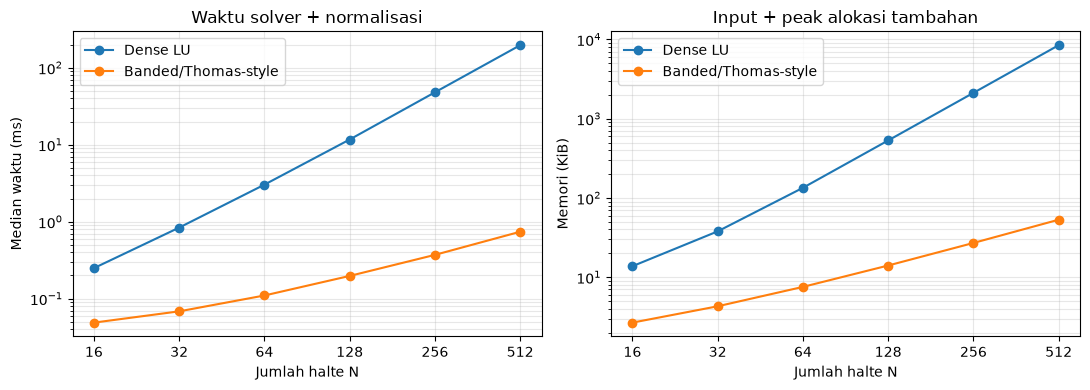

In [15]:
fig_performance, axes_performance = plt.subplots(1, 2, figsize=(11, 4))
for method, label in (("dense", "Dense LU"), ("banded", "Banded/Thomas-style")):
    sizes = [row["N"] for row in performance_results]
    times_ms = [row[method]["seconds"] * 1000 for row in performance_results]
    memory_kib = [row[method]["peak_total_bytes"] / 1024 for row in performance_results]
    axes_performance[0].plot(sizes, times_ms, marker="o", label=label)
    axes_performance[1].plot(sizes, memory_kib, marker="o", label=label)
for ax, title, ylabel in zip(
    axes_performance,
    ("Waktu solver + normalisasi", "Input + peak alokasi tambahan"),
    ("Median waktu (ms)", "Memori (KiB)"),
):
    ax.set_title(title)
    ax.set_xlabel("Jumlah halte N")
    ax.set_ylabel(ylabel)
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(MATRIX_SIZES, labels=[str(N) for N in MATRIX_SIZES])
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
fig_performance.tight_layout()
fig_performance.savefig(OUTPUT_DIR / "kinerja.png", dpi=180, bbox_inches="tight")
plt.show()


**Interpretasi hasil:** Pada eksekusi ini, solver banded menggunakan waktu dan
memori terukur yang lebih kecil daripada solver dense untuk seluruh ukuran
matriks. Kedua metode menghasilkan distribusi stasioner yang sama hingga
presisi hasil perhitungan; pemeriksaan normalisasi dan residual stasioner
lolos untuk semua ukuran. Angka memori mencakup input solver dan peak alokasi
tambahan yang terlacak, bukan keseluruhan memori notebook. Waktu tidak
mencakup ekstraksi compact dari matriks dense dan dapat berubah ketika
notebook dijalankan kembali.

## 6. Analisis Kompleksitas — vi)

### Dense LU
Pada kolom $k$ (indeks nol), ada $N-k-1$ baris yang diperbarui, masing-masing
sepanjang $N-k$. Perkalian dan pengurangan memberi sekitar
$$2\sum_{k=0}^{N-2}(N-k-1)(N-k)
=\frac23(N^3-N)$$
operasi, ditambah pembagian $O(N^2)$. Jadi faktorisasi $\Theta(N^3)$,
pencarian pivot $O(N^2)$, serta substitusi maju/mundur dan $Pb$ eksplisit
$O(N^2)$. Normalisasi $O(N)$. Matriks $B,P,L,U$ berukuran $N^2$,
sehingga input dan ruang kerja total $\Theta(N^2)$. Kode ini tetap memperbarui
baris meski multiplier nol; struktur band tidak mengurangi jumlah operasi dense.

### Banded dengan partial pivoting
Untuk bandwidth umum $(p,q)$, pivot dicari pada paling banyak $p+1$ baris.
Setelah pivoting, $U$ dapat melebar sampai $p+q$ diagonal atas. Setiap langkah
memperbarui paling banyak $p$ baris dengan jangkauan $p+q+1$ koefisien:
$$O\bigl(N[1+p+p(p+q+1)]\bigr).$$
Untuk $p\ge1$, batas dominannya biasa ditulis $O(Np(p+q))$.
Substitusi memerlukan $O(N(p+q+1))$, dan penyimpanan band/fill/pivot/rhs
$O(N(2p+q+1))$. Formula ini berlaku untuk algoritma banded umum;
implementasi repo **khusus kapasitas $p=1,q=2$**, sehingga faktorisasi,
validasi vektor, substitusi, dan normalisasi semuanya $\Theta(N)$,
dengan memori $\Theta(N)$. Lima vektor koefisien sepanjang $N$ menyimpan
lower, diagonal, dua upper input, dan satu upper fill. Thomas klasik
($p=q=1$) juga linear, tetapi partial pivoting tetap memerlukan upper fill.

### Hubungan dengan eksperimen
Untuk $N\mapsto2N$, FLOPs dense mendekati faktor 8, memori dense faktor 4,
sedangkan banded dengan lebar tetap mendekati faktor 2. Waktu riil Python
tidak harus mengikuti FLOPs persis: loop baris dense berjumlah $\Theta(N^2)$,
sementara pembaruan vektor dilakukan NumPy. Pada rentang 16–512, overhead
loop, cache, timer, dan penjadwalan dapat menghasilkan rasio waktu mendekati
4 atau fluktuasi pada ukuran kecil. Ini tidak mengubah kompleksitas algoritma.

Pembacaan CSV dense, penyimpanan $T,A,B$, deteksi bandwidth, dan ekstraksi
compact dalam notebook masih memakai waktu/memori $O(N^2)$; keuntungan
linear di atas berlaku pada **solver yang menerima input compact**.
Pengukuran condition number bagian vii dilakukan terpisah dari benchmark.


In [16]:
complexity_results = []
print("N | FLOPs update dense | slot B dense | slot B band | slot kerja band+fill | rasio waktu | rasio memori")
for row in performance_results:
    N = row["N"]
    dense_flops = 2 * (N**3 - N) // 3
    record = {
        "N": N, "dense_update_flops": dense_flops,
        "dense_coefficient_slots": N*N, "band_input_slots": 4*N-4,
        "band_work_coefficient_slots": 5*N,
        "speedup": row["dense"]["seconds"] / row["banded"]["seconds"],
        "memory_ratio": row["dense"]["peak_total_bytes"] / row["banded"]["peak_total_bytes"],
    }
    complexity_results.append(record)
    print(f"{N} | {dense_flops} | {N*N} | {4*N-4} | {5*N} | "
          f"{record['speedup']:.2f}x | {record['memory_ratio']:.2f}x")
print("Rasio waktu terukur untuk setiap penggandaan N (dense, banded):")
for previous, current in zip(performance_results, performance_results[1:]):
    print(f"{previous['N']} -> {current['N']}: "
          f"{current['dense']['seconds']/previous['dense']['seconds']:.2f}, "
          f"{current['banded']['seconds']/previous['banded']['seconds']:.2f}")


N | FLOPs update dense | slot B dense | slot B band | slot kerja band+fill | rasio waktu | rasio memori
16 | 2720 | 256 | 60 | 80 | 5.10x | 5.15x
32 | 21824 | 1024 | 124 | 160 | 12.25x | 8.82x
64 | 174720 | 4096 | 252 | 320 | 27.54x | 17.80x
128 | 1398016 | 16384 | 508 | 640 | 59.20x | 37.86x
256 | 11184640 | 65536 | 1020 | 1280 | 129.45x | 78.34x
512 | 89478144 | 262144 | 2044 | 2560 | 265.09x | 159.19x
Rasio waktu terukur untuk setiap penggandaan N (dense, banded):
16 -> 32: 3.36, 1.40
32 -> 64: 3.61, 1.61
64 -> 128: 3.86, 1.80
128 -> 256: 4.10, 1.88
256 -> 512: 4.09, 2.00


## 7. Analisis Kondisi dan Galat — vii)

Gunakan norma infinity untuk semua ukuran dan kedua solver:
$$\|v\|_\infty=\max_i|v_i|,\quad
\|M\|_\infty=\max_i\sum_j|M_{ij}|,\quad
\kappa_\infty(B)=\|B\|_\infty\|B^{-1}\|_\infty.$$
Tidak ada `np.linalg.cond` atau `inv`. Untuk setiap $j$, selesaikan
$Bx^{(j)}=e_j$ dengan solver compact buatan sendiri. Kolom $x^{(j)}$
adalah kolom ke-$j$ dari inverse; akumulasikan $s_i=\sum_j|x_i^{(j)}|$,
sehingga $\|B^{-1}\|_\infty=\max_i s_i$. Inverse dense tidak disimpan.
Ini menghitung norma inverse lengkap dalam float64, bukan estimator beberapa
iterasi. Biaya diagnostik adalah $N$ pemanggilan solver linear, yakni
$O(N^2)$ waktu dan $O(N)$ ruang tambahan untuk bandwidth tetap.
Biaya ini **tidak** dimasukkan pada eksperimen waktu solver bagian v.

Ukur $r=\|T^T\pi-\pi\|_\infty$,
$e_{\rm norm}=|\sum_i\pi_i-1|$, serta
$\delta_\pi=\|\pi_{dense}-\pi_{banded}\|_\infty$.
Sebagai pemeriksaan tambahan, ukur residual SPL sebelum normalisasi
$\rho=\|B\hat z-b\|_\infty$ dan backward error terskala
$$\eta=\frac{\|B\hat z-b\|_\infty}
{\|B\|_\infty\|\hat z\|_\infty+\|b\|_\infty}.$$
Nilai ini tidak sama dengan residual stasioner. Untuk sistem nonsingular,
galat maju relatif solusi $z$ memenuhi batas residual-only
$\|\hat z-z\|_\infty/\|z\|_\infty\le
\kappa_\infty(B)\rho/\|b\|_\infty$ dalam aritmetika eksak.
Di sini $\|b\|_\infty=1$. Batas tersebut dapat longgar dan bukan batas
langsung untuk $\pi$ setelah normalisasi. Residual kecil maupun dua solver
yang memberi hasil identik tidak menjamin galat maju kecil.


In [17]:
def vector_inf(v):
    return float(np.max(np.abs(v)))


def matrix_inf(M):
    return float(np.max(np.sum(np.abs(M), axis=1)))


def compact_matvec(bands, x):
    """Perkalian koefisien B asli dengan vektor, tanpa alokasi dense."""
    result = bands["diag"] * x
    result[1:] += bands["lower1"][:-1] * x[:-1]
    result[:-1] += bands["upper1"][:-1] * x[1:]
    result[:-2] += bands["upper2"][:-2] * x[2:]
    return result


def condition_number_inf(B, bands):
    """Norma inverse melalui N solusi basis; semua solver diimplementasikan sendiri."""
    N = B.shape[0]
    norm_B = matrix_inf(B)
    absolute_row_sums = np.zeros(N)
    rhs = np.zeros(N)
    max_column_residual = 0.0
    max_column_backward_error = 0.0
    for j in range(N):
        rhs.fill(0.0)
        rhs[j] = 1.0
        column = solve_banded(bands, rhs)
        absolute_row_sums += np.abs(column)
        residual = vector_inf(compact_matvec(bands, column) - rhs)
        eta = residual / (norm_B * vector_inf(column) + 1.0)
        max_column_residual = max(max_column_residual, residual)
        max_column_backward_error = max(max_column_backward_error, eta)
    norm_inverse = float(np.max(absolute_row_sums))
    kappa = norm_B * norm_inverse
    assert np.isfinite(kappa) and kappa >= 1.0 - TOL
    assert max_column_backward_error <= TOL
    return kappa, norm_B, norm_inverse, max_column_residual, max_column_backward_error


# B dari contoh dua halte mempunyai inverse [[1,0],[0.5,2]], kappa_inf=2.5.
_, B_small, _ = build_system(np.array([[0.75, 0.25], [0.5, 0.5]]))
kappa_small, *_ = condition_number_inf(B_small, extract_banded_storage(B_small, 1, 2))
assert abs(kappa_small - 2.5) <= TOL
assert abs(condition_number_inf(np.eye(3), extract_banded_storage(np.eye(3), 1, 2))[0] - 1) <= TOL
print("Uji analitik condition number: OK (2.5 dan 1)")

condition_results = []
accuracy_results = []
print("N | kappa_inf(B) | norm B | norm inverse | max residual kolom inverse | max eta kolom")
for N in MATRIX_SIZES:
    _, B, b = systems[N]
    bands = extract_banded_storage(B, 1, 2)
    kappa, norm_B, norm_inverse, column_residual, column_eta = condition_number_inf(B, bands)
    condition_results.append({
        "N": N, "kappa_inf": kappa, "norm_B_inf": norm_B,
        "norm_inverse_inf": norm_inverse, "inverse_column_residual_inf": column_residual,
        "inverse_column_backward_error": column_eta,
    })
    print(f"{N} | {kappa:.6e} | {norm_B:.6e} | {norm_inverse:.6e} | {column_residual:.3e} | {column_eta:.3e}")
    for method, solver, coefficients in (("dense", solve_dense, B), ("banded", solve_banded, bands)):
        z = solver(coefficients, b)
        pi = normalize_solution(z)
        rho = vector_inf(B @ z - b)
        eta = rho / (norm_B * vector_inf(z) + vector_inf(b))
        record = {
            "N": N, "method": method,
            "stationary_residual_inf": vector_inf(matrices[N].T @ pi - pi),
            "relative_stationary_residual_inf": vector_inf(matrices[N].T @ pi - pi) / vector_inf(pi),
            "normalization_error": float(abs(np.sum(pi) - 1)),
            "system_residual_inf": rho, "backward_error": eta,
            "relative_z_error_bound": kappa * rho / vector_inf(b),
            "minimum_pi": float(np.min(pi)),
            "dense_banded_difference_inf": max_abs_diff(performance_solutions[N]["dense"], performance_solutions[N]["banded"]),
        }
        assert record["stationary_residual_inf"] <= TOL
        assert record["normalization_error"] <= TOL
        assert record["minimum_pi"] >= -TOL and eta <= TOL
        accuracy_results.append(record)
print("\nN | solver | r_inf | e_norm | rho_SPL | eta | batas galat relatif z | delta_pi")
for row in accuracy_results:
    print(f"{row['N']} | {row['method']} | {row['stationary_residual_inf']:.3e} | "
          f"{row['normalization_error']:.3e} | {row['system_residual_inf']:.3e} | "
          f"{row['backward_error']:.3e} | {row['relative_z_error_bound']:.3e} | "
          f"{row['dense_banded_difference_inf']:.3e}")


Uji analitik condition number: OK (2.5 dan 1)
N | kappa_inf(B) | norm B | norm inverse | max residual kolom inverse | max eta kolom
16 | 1.066300e+03 | 1.000000e+00 | 1.066300e+03 | 2.220e-15 | 4.661e-17
32 | 4.153235e+03 | 1.000000e+00 | 4.153235e+03 | 8.438e-15 | 5.746e-17
64 | 1.638588e+04 | 1.000000e+00 | 1.638588e+04 | 1.599e-14 | 7.311e-17
128 | 6.509208e+04 | 1.000000e+00 | 6.509208e+04 | 4.263e-14 | 6.838e-17
256 | 1.072384e+09 | 1.000000e+00 | 1.072384e+09 | 4.948e-10 | 8.199e-17


512 | 1.036101e+06 | 1.000000e+00 | 1.036101e+06 | 3.411e-13 | 8.390e-17

N | solver | r_inf | e_norm | rho_SPL | eta | batas galat relatif z | delta_pi
16 | dense | 1.388e-17 | 0.000e+00 | 2.776e-17 | 1.329e-17 | 2.960e-14 | 0.000e+00
16 | banded | 1.388e-17 | 0.000e+00 | 2.776e-17 | 1.329e-17 | 2.960e-14 | 0.000e+00
32 | dense | 6.939e-18 | 0.000e+00 | 5.551e-17 | 2.658e-17 | 2.306e-13 | 0.000e+00
32 | banded | 6.939e-18 | 0.000e+00 | 5.551e-17 | 2.658e-17 | 2.306e-13 | 0.000e+00
64 | dense | 6.939e-18 | 0.000e+00 | 8.327e-17 | 3.987e-17 | 1.364e-12 | 0.000e+00
64 | banded | 6.939e-18 | 0.000e+00 | 8.327e-17 | 3.987e-17 | 1.364e-12 | 0.000e+00
128 | dense | 1.735e-18 | 0.000e+00 | 5.551e-17 | 2.658e-17 | 3.613e-12 | 0.000e+00
128 | banded | 1.735e-18 | 0.000e+00 | 5.551e-17 | 2.658e-17 | 3.613e-12 | 0.000e+00
256 | dense | 8.674e-19 | 0.000e+00 | 5.551e-17 | 2.658e-17 | 5.953e-08 | 0.000e+00
256 | banded | 8.674e-19 | 0.000e+00 | 5.551e-17 | 2.658e-17 | 5.953e-08 | 0.000e+00
512 | de

### Verifikasi independen dan bottleneck pada $N=256$

Selain controlled test, uji 120 matriks band acak memakai seed tetap.
Pilih $z_\star$ terlebih dahulu, bentuk $b=Bz_\star$, lalu bandingkan hasil
kedua solver dengan $z_\star$, termasuk kasus pivot nol dan banyak swap.

Untuk data Markov, gunakan pemeriksaan independen berdasarkan keseimbangan
arus pada potongan koridor (bukan eliminasi LU). Karena transisi ke kanan
maksimal satu halte dan ke kiri maksimal dua halte, keseimbangan arus
melintasi batas $i$ dan $i+1$ memberikan
$$\pi_iT_{i,i+1}=
\pi_{i+1}(T_{i+1,i}+T_{i+1,i-1})+
\pi_{i+2}T_{i+2,i},$$
dengan suku di luar rentang dianggap nol. Mulai dari bobot $w_N=1$, hitung
bobot mundur, lalu normalkan. Operasi ini menggunakan `decimal` 60 digit dan
penjumlahan koefisien nonnegatif, sehingga tidak mengalami cancellation.

**Batas acuan arus:** CSV bersifat stochastic hingga pembulatan float64.
Acuan arus menggunakan koefisien off-diagonal float64 yang sama dan secara
implisit diagonal $1-\sum_{j\ne i}T_{ij}$. Jadi acuan ini tepat untuk matriks
dengan jumlah baris seimbang, berbeda paling besar sekitar $10^{-16}$ pada
diagonal dari data asli. Selisih yang dilaporkan bukan galat maju tersertifikasi
terhadap $B$ asli. Pada matriks berkondisi buruk, perubahan sekecil ini juga
dapat terlihat pada solusi. Data asli tetap tidak diubah oleh solver.


In [18]:
from decimal import Decimal, localcontext


def stationary_flux_reference(T):
    N = T.shape[0]
    assert matrix_bandwidth(T)[0] <= 2 and matrix_bandwidth(T)[1] <= 1
    with localcontext() as context:
        context.prec = 60
        weights = [Decimal(0) for _ in range(N)]
        weights[-1] = Decimal(1)
        D = lambda x: Decimal.from_float(float(x))
        for i in range(N - 2, -1, -1):
            incoming = D(T[i+1, i])
            if i > 0:
                incoming += D(T[i+1, i-1])
            numerator = weights[i+1] * incoming
            if i+2 < N:
                numerator += weights[i+2] * D(T[i+2, i])
            denominator = D(T[i, i+1])
            if denominator <= 0:
                raise ValueError("Acuan arus memerlukan semua perpindahan satu halte ke kanan positif.")
            weights[i] = numerator / denominator
        total = sum(weights)
        return np.array([float(w / total) for w in weights])


rng = np.random.default_rng(20261003)
random_test_error, random_test_swaps = 0.0, 0
for n in (2, 3, 5, 8, 16, 32):
    for trial in range(20):
        M = np.zeros((n, n))
        for i in range(n):
            for j in range(max(0, i-1), min(n, i+3)):
                M[i, j] = rng.uniform(-2, 2)
        if trial % 2 == 0:
            M[0, 0] = 0.0
        expected = rng.uniform(-1, 1, n)
        rhs = M @ expected
        x_band, info = solve_banded(extract_banded_storage(M, 1, 2), rhs, return_info=True)
        x_dense = solve_dense(M, rhs)
        error = max(max_abs_diff(x_band, expected), max_abs_diff(x_dense, expected))
        assert error < 1e-9
        random_test_error = max(random_test_error, error)
        random_test_swaps += info["pivot_swaps"]
print(f"120 uji acak: OK; max galat={random_test_error:.3e}; total swap={random_test_swaps}")

flux_results = []
for N in MATRIX_SIZES:
    reference = stationary_flux_reference(matrices[N])
    difference = max_abs_diff(reference, performance_solutions[N]["banded"])
    assert difference < 1e-8  # Data asli vs diagonal seimbang pada matriks sensitif.
    flux_results.append({"N": N, "difference_to_balanced_flux_reference_inf": difference})
    print(f"N={N}: selisih acuan arus 60 digit = {difference:.3e}")

T256 = matrices[256]
left, right = np.arange(128), np.arange(128, 256)
cross_lr = T256[np.ix_(left, right)]
cross_rl = T256[np.ix_(right, left)]
print("Transisi positif yang melintasi potongan 128 | 129:")
for sources, targets, values in ((left, right, cross_lr), (right, left, cross_rl)):
    rows, columns = np.nonzero(values)
    for i, j in zip(rows, columns):
        print(f"{sources[i]+1} -> {targets[j]+1}: {values[i,j]:.9e}")

# Perturbasi satu peluang; kompensasi di diagonal menjaga jumlah baris.
T_perturbed = T256.copy()
probability_change = T256[127, 128] * 1e-6
T_perturbed[127, 128] += probability_change
T_perturbed[127, 127] -= probability_change
validate_transition_matrix(T_perturbed, 256)
_, B_perturbed, b_perturbed = build_system(T_perturbed)
pi_perturbed = normalize_solution(solve_banded(extract_banded_storage(B_perturbed, 1, 2), b_perturbed))
original_pi = performance_solutions[256]["banded"]
pi_change_relative = vector_inf(pi_perturbed - original_pi) / vector_inf(original_pi)
_, B256, _ = systems[256]
B_change_relative = matrix_inf(B_perturbed - B256) / matrix_inf(B256)
print(f"Perturbasi relatif B={B_change_relative:.3e}; perubahan relatif pi={pi_change_relative:.3e}")
print(f"Massa halte 1..128: {sum(original_pi[:128]):.9f} -> {sum(pi_perturbed[:128]):.9f}")


120 uji acak: OK; max galat=2.721e-11; total swap=602
N=16: selisih acuan arus 60 digit = 7.216e-16
N=32: selisih acuan arus 60 digit = 4.510e-16
N=64: selisih acuan arus 60 digit = 1.308e-15
N=128: selisih acuan arus 60 digit = 8.656e-16
N=256: selisih acuan arus 60 digit = 3.307e-12
N=512: selisih acuan arus 60 digit = 6.679e-16
Transisi positif yang melintasi potongan 128 | 129:
128 -> 129: 1.189477679e-07
129 -> 127: 2.000000000e-08
129 -> 128: 8.000000000e-08
130 -> 128: 2.000000000e-08
Perturbasi relatif B=1.189e-13; perubahan relatif pi=5.610e-07
Massa halte 1..128: 0.610906882 -> 0.610906645


**Analisis hasil.** Condition number meningkat dari sekitar $1.07\times10^3$
pada $N=16$ menjadi $1.04\times10^6$ pada $N=512$, dengan pengecualian
$N=256$ yang mencapai sekitar $1.07\times10^9$. Ini bukan fungsi ukuran
semata: transisi $128\to129$ sekitar $1.19\times10^{-7}$, sedangkan
$129\to127$, $129\to128$, dan $130\to128$ hanya $2\times10^{-8}$,
$8\times10^{-8}$, dan $2\times10^{-8}$. Dua bagian koridor nyaris menjadi
kelas tertutup terpisah. Kondisi tersebut membuat arah stasioner peka
terhadap perubahan kecil pada koefisien, walaupun rantai tetap irreducible.

Residual stasioner kedua metode mendekati presisi mesin dan seluruh
galat normalisasi kecil. Perbedaan kedua solver nol pada eksekusi ini
karena urutan operasi efektif pada band sama; keduanya dapat berbagi
galat pembulatan. Acuan arus independen menunjukkan kesesuaian sangat baik,
tetapi selisih lebih besar pada $N=256$ sesuai sensitivitas terhadap
pembulatan jumlah baris. Demonstrasi perturbasi menunjukkan sensitivitas
yang benar-benar teramati; angka condition number adalah batas kasus
terburuk, bukan faktor amplifikasi yang selalu dicapai.

Residual absolut kolom inverse pada $N=256$ dapat melebihi `TOL` karena
nilai kolom inverse sangat besar. Backward error **terskala** tetap kecil;
itu alasan pemeriksaan condition number memakai ukuran terskala.
Partial pivoting menekan multiplier eliminasi ($|m|\le1$) dan menghindari
pivot nol, tetapi tidak menghilangkan conditioning buruk pada input.


Residual absolut juga mengikuti skala komponen $\pi$, yang menurun sekitar
$1/N$. Karena itu, residual absolut yang makin kecil pada $N$ besar tidak
berarti akurasi relatif otomatis membaik. CSV galat juga memuat residual
stasioner relatif $r/\|\pi\|_\infty$ untuk membantu perbandingan.


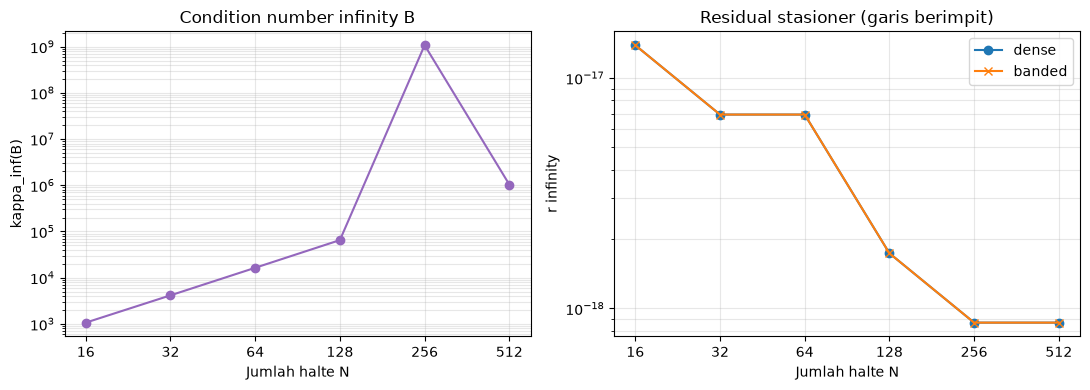

In [19]:
fig_accuracy, axes_accuracy = plt.subplots(1, 2, figsize=(11, 4))
axes_accuracy[0].loglog(MATRIX_SIZES, [row["kappa_inf"] for row in condition_results], "o-", color="tab:purple")
axes_accuracy[0].set_title("Condition number infinity B")
axes_accuracy[0].set_ylabel("kappa_inf(B)")
floor_for_plot = 1e-20  # Hanya untuk grafik log; nilai tabel/CSV tetap asli.
for method, marker in (("dense", "o"), ("banded", "x")):
    rows = [row for row in accuracy_results if row["method"] == method]
    axes_accuracy[1].loglog(MATRIX_SIZES, [max(row["stationary_residual_inf"], floor_for_plot) for row in rows], marker+"-", label=method)
axes_accuracy[1].set_title("Residual stasioner (garis berimpit)")
axes_accuracy[1].set_ylabel("r infinity")
axes_accuracy[1].legend()
for ax in axes_accuracy:
    ax.set_xlabel("Jumlah halte N")
    ax.set_xscale("log", base=2)
    ax.set_xticks(MATRIX_SIZES, labels=[str(n) for n in MATRIX_SIZES])
    ax.grid(True, which="both", alpha=0.3)
fig_accuracy.tight_layout()
fig_accuracy.savefig(OUTPUT_DIR / "kondisi_galat.png", dpi=180, bbox_inches="tight")
plt.show()
